<a href="https://colab.research.google.com/github/nasyathav/ANALISA-SEGMENTASI-DESTINASI-WISATA-SKRIPSI-/blob/main/SEGMENTASI_DESTINASI_WISATA_JATENG_SIDANG_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Library Pengolahan Data
import pandas as pd
import numpy as np

# Library Visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

# Library Clustering
from sklearn.cluster import KMeans

# Library Normalisasi
from sklearn.preprocessing import MinMaxScaler

# Library Evaluasi
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
df = pd.read_excel('/content/data penelitian all.xlsx')

In [ ]:
df.head()

,No,Tahun,Nama Destinasi Wisata,Jenis Wisata,Nusantara,Mancanegara,Jumlah Pengunjung,Pendapatan
0,1,2021,Agro Wisata Kopeng Gunungsari,Wisata Buatan,8210,0,8210,14922000.0
1,2,2021,Agro Wisata Tlogo Resort,Wisata Buatan,8941,0,8941,164398000.0
2,3,2021,Air Terjun Curug Lawe,Wisata Alam,5332,0,5332,NaN
3,4,2021,Air Terjun Semirang,Wisata Alam,40002,0,40002,NaN
4,5,2021,Ayanaz,Wisata Buatan,16608,0,16608,562370000.0


In [ ]:
df.info()
# Fungsinya untuk menampilkan informasi umum tentang dataset agar mengetahui kondisi dataset.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   No                     243 non-null    int64  
 1   Tahun                  243 non-null    int64  
 2   Nama Destinasi Wisata  243 non-null    object 
 3   Jenis Wisata           243 non-null    object 
 4   Nusantara              243 non-null    int64  
 5   Mancanegara            243 non-null    int64  
 6   Jumlah Pengunjung      243 non-null    int64  
 7   Pendapatan             133 non-null    float64
dtypes: float64(1), int64(5), object(2)
memory usage: 15.3+ KB


# **PRE PROCESSING**

In [ ]:
# Mengecek Missing Value
df.isnull().sum()

,0
No,0
Tahun,0
Nama Destinasi Wisata,0
Jenis Wisata,0
Nusantara,0
Mancanegara,0
Jumlah Pengunjung,0
Pendapatan,110


In [ ]:
# Menghapus missing value.
df = df.dropna()

In [ ]:
# Mengecek Missing Value
df.isnull().sum()

,0
No,0
Tahun,0
Nama Destinasi Wisata,0
Jenis Wisata,0
Nusantara,0
Mancanegara,0
Jumlah Pengunjung,0
Pendapatan,0


In [ ]:
# Menghapus Rp, titik, koma, dan spasi
df['Pendapatan'] = (
    df['Pendapatan']
    .astype(str)
    .str.replace('Rp', '', regex=False)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .str.replace('-', '0', regex=False)
    .str.strip()
)

df['Nusantara'] = (
    df['Nusantara']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .str.strip()
)

df['Mancanegara'] = (
    df['Mancanegara']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .str.strip()
)

# Mengubah menjadi numerik
df['Pendapatan'] = pd.to_numeric(df['Pendapatan'])
df['Nusantara'] = pd.to_numeric(df['Nusantara'])
df['Mancanegara'] = pd.to_numeric(df['Mancanegara'])
df['Jumlah Pengunjung'] = pd.to_numeric(df['Jumlah Pengunjung'])

In [ ]:
# Memilih atribut yang digunakan pada proses clustering
data_cluster = df[[
                  'Tahun',
                  'Jumlah Pengunjung',
                  'Pendapatan']]

data_cluster.head()


,Tahun,Jumlah Pengunjung,Pendapatan
0,2021,8210,149220000
1,2021,8941,1643980000
4,2021,16608,5623700000
5,2021,1086,118600000
7,2021,61308,14106498700


In [ ]:
# Normalisasi Min-Max

# Membuat objek MinMaxScaler
scaler = MinMaxScaler()

# Melakukan normalisasi data
data_scaled = scaler.fit_transform(data_cluster)

# Mengubah hasil normalisasi menjadi DataFrame
data_scaled = pd.DataFrame(
    data_scaled,
    columns=data_cluster.columns
)

# Menampilkan hasil normalisasi
data_scaled.head()

,Tahun,Jumlah Pengunjung,Pendapatan
0,0.0,0.010884,0.000501
1,0.0,0.011877,0.005877
2,0.0,0.022294,0.020190
3,0.0,0.001204,0.000391
4,0.0,0.083030,0.050700


# **MENENTUKAN JUMLAH CLUSTER DENGAN ELBOW METHOD**

In [ ]:
# Install library (cukup sekali dijalankan)
!pip install kneed

# Import library
from kneed import KneeLocator

# Menyimpan nilai SSE
sse = []

# Menentukan rentang jumlah cluster
K = range(1, 10)

# Menghitung SSE untuk setiap nilai K
for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(data_scaled)

    # Menyimpan nilai SSE
    sse.append(kmeans.inertia_)

# Menentukan titik elbow secara otomatis
kl = KneeLocator(
    K,
    sse,
    curve='convex',
    direction='decreasing'
)

# Jumlah cluster yang dipilih
optimal_k = kl.elbow

# Nilai SSE pada cluster terpilih
optimal_sse = sse[K.index(optimal_k)]

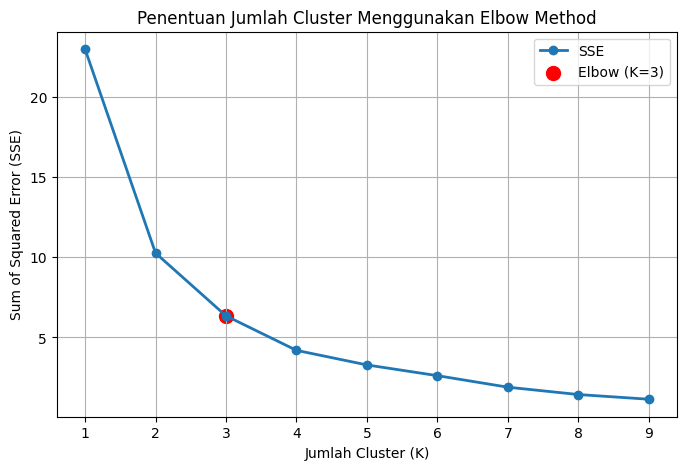

Jumlah cluster yang dipilih : 3
Nilai SSE pada K = 3 : 6.346


In [ ]:
# Visualisasi Metode Elbow dan SSE

plt.figure(figsize=(8,5))

plt.plot(
    K,
    sse,
    marker='o',
    linewidth=2,
    label='SSE'
)

# Menandai titik elbow
plt.scatter(
    optimal_k,
    optimal_sse,
    color='red',
    s=100,
    label=f'Elbow (K={optimal_k})'
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Sum of Squared Error (SSE)")
plt.title("Penentuan Jumlah Cluster Menggunakan Elbow Method")

plt.grid(True)
plt.legend()

plt.show()

print(f"Jumlah cluster yang dipilih : {optimal_k}")
print(f"Nilai SSE pada K = {optimal_k} : {optimal_sse:.3f}")

Nilai SSE inilah yang menjadi dasar penentuan titik Elbow pada Gambar, di mana semakin kecil nilai SSE pada suatu jumlah cluster (K), maka semakin kompak anggota di dalam cluster tersebut. Sebagai ilustrasi perhitungan algoritma K-Means dengan jumlah cluster yang sesuai dengan hasil penelitian (K=3)

# **EVALUASI HASIL CLUSTERING**

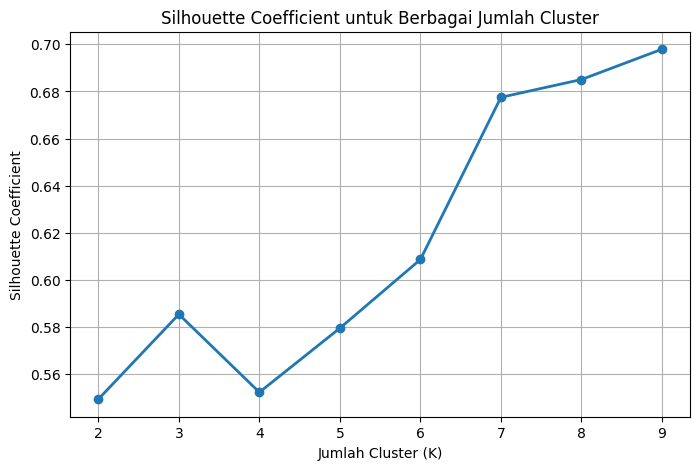

Cluster terbaik berdasarkan Silhouette : 9
Nilai Silhouette : 0.697921241986873


In [ ]:
# Silhouette Coefficient

silhouette_scores = []

K = range(2, 10)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, labels)
    silhouette_scores.append(score)

# Menampilkan grafik
plt.figure(figsize=(8,5))

plt.plot(
    K,
    silhouette_scores,
    marker='o',
    linewidth=2
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Silhouette Coefficient")
plt.title("Silhouette Coefficient untuk Berbagai Jumlah Cluster")

plt.grid(True)

plt.show()

# Nilai terbaik
best_k = K[np.argmax(silhouette_scores)]

print("Cluster terbaik berdasarkan Silhouette :", best_k)
print("Nilai Silhouette :", max(silhouette_scores))

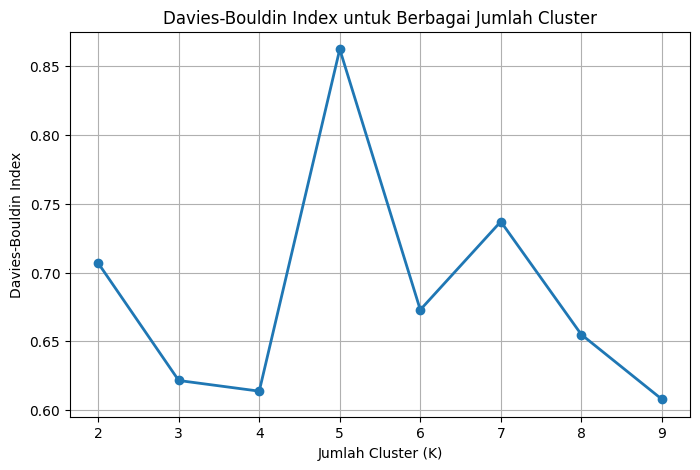

Cluster terbaik berdasarkan DBI : 9
Nilai DBI : 0.6078810736372416


In [ ]:
# Davies-Bouldin Index

dbi_scores = []

K = range(2,10)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(data_scaled)
    dbi = davies_bouldin_score(data_scaled, labels)
    dbi_scores.append(dbi)

# Membuat grafik
plt.figure(figsize=(8,5))

plt.plot(
    K,
    dbi_scores,
    marker='o',
    linewidth=2
)

plt.xlabel("Jumlah Cluster (K)")
plt.ylabel("Davies-Bouldin Index")
plt.title("Davies-Bouldin Index untuk Berbagai Jumlah Cluster")

plt.grid(True)

plt.show()

best_k = K[np.argmin(dbi_scores)]

print("Cluster terbaik berdasarkan DBI :", best_k)
print("Nilai DBI :", min(dbi_scores))

# **IMPLEMENTASI K-MEANS CLUSTERING**

In [ ]:
# Membuat model K-Means
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
)

# Melakukan proses clustering
cluster = kmeans.fit_predict(data_scaled)

# Menambahkan hasil cluster ke dataset
df['Cluster'] = cluster
print(f"\nJumlah Cluster yang Digunakan : {optimal_k}")

print("\nJumlah Data pada Setiap Cluster")
print(df['Cluster'].value_counts().sort_index())

print("\nCentroid Akhir (Skala Normalisasi)")
centroid = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=data_scaled.columns
)
display(centroid)

print("\nHasil Clustering")
display(df.head())


Jumlah Cluster yang Digunakan : 3

Jumlah Data pada Setiap Cluster
Cluster
0    56
1    45
2    32
Name: count, dtype: int64

Centroid Akhir (Skala Normalisasi)


,Tahun,Jumlah Pengunjung,Pendapatan
0,3.482143e-01,0.123237,0.080303
1,8.666667e-01,0.098059,0.063930
2,2.775558e-16,0.033209,0.019342



Hasil Clustering


,No,Tahun,Nama Destinasi Wisata,Jenis Wisata,Nusantara,Mancanegara,Jumlah Pengunjung,Pendapatan,Cluster
0,1,2021,Agro Wisata Kopeng Gunungsari,Wisata Buatan,8210,0,8210,149220000,2
1,2,2021,Agro Wisata Tlogo Resort,Wisata Buatan,8941,0,8941,1643980000,2
4,5,2021,Ayanaz,Wisata Buatan,16608,0,16608,5623700000,2
5,6,2021,Bamboo Garden Sumowono,Wisata Buatan,1086,0,1086,118600000,2
7,8,2021,Bukit Cinta,Wisata Buatan,61308,0,61308,14106498700,2


# **VISUALISASI HASIL CLUSTERING**

**Karakteristik Clustering**

In [ ]:
summary = (
    df.groupby("Cluster")
    .agg(
       ** {
            "Jumlah Destinasi": ("Nama Destinasi Wisata", "count"),
            "Rata-rata Pengunjung": ("Jumlah Pengunjung", "mean"),
            "Rata-rata Pendapatan": ("Pendapatan", "mean"),
        }
    )
    .round(2)
    .reset_index()
)

# Urutkan berdasarkan rata-rata pengunjung
summary = summary.sort_values(
    by="Rata-rata Pengunjung",
    ascending=True
).reset_index(drop=True)

karakteristik = []
strategi = []

for i in range(len(summary)):

    # Cluster dengan pengunjung paling sedikit
    if i == 0:

        karakteristik.append(
            "Destinasi Potensial (Pengunjung dan Pendapatan Rendah)" )
        strategi.append(
            "Menjadi prioritas pengembangan melalui peningkatan fasilitas, promosi digital, dan aksesibilitas." )

    # Cluster tengah
    elif i == 1:

        karakteristik.append(
            "Destinasi Berkembang (Pengunjung dan Pendapatan Menengah)" )
        strategi.append(
            "Meningkatkan kualitas layanan, memperkuat promosi, dan mengembangkan atraksi wisata." )

    # Cluster tertinggi
    else:

        karakteristik.append(
            "Destinasi Unggulan (Pengunjung dan Pendapatan Tinggi)" )
        strategi.append(
            "Mempertahankan kualitas layanan, meningkatkan inovasi, serta memperluas promosi sebagai destinasi unggulan." )

summary["Karakteristik"] = karakteristik
summary["Strategi"] = strategi

display(summary)

summary

,Cluster,Jumlah Destinasi,Rata-rata Pengunjung,Rata-rata Pendapatan,Karakteristik,Strategi
0,2,32,24640.69,5.387830e+09,Destinasi Potensial (Pengunjung dan Pendapatan...,Menjadi prioritas pengembangan melalui peningk...
1,1,45,72369.04,1.778506e+10,Destinasi Berkembang (Pengunjung dan Pendapata...,"Meningkatkan kualitas layanan, memperkuat prom..."
2,0,56,90899.82,2.233737e+10,Destinasi Unggulan (Pengunjung dan Pendapatan ...,"Mempertahankan kualitas layanan, meningkatkan ..."


,Cluster,Jumlah Destinasi,Rata-rata Pengunjung,Rata-rata Pendapatan,Karakteristik,Strategi
0,2,32,24640.69,5.387830e+09,Destinasi Potensial (Pengunjung dan Pendapatan...,Menjadi prioritas pengembangan melalui peningk...
1,1,45,72369.04,1.778506e+10,Destinasi Berkembang (Pengunjung dan Pendapata...,"Meningkatkan kualitas layanan, memperkuat prom..."
2,0,56,90899.82,2.233737e+10,Destinasi Unggulan (Pengunjung dan Pendapatan ...,"Mempertahankan kualitas layanan, meningkatkan ..."


In [ ]:
for cluster in sorted(df["Cluster"].unique()):

    print(f"CLUSTER {cluster}")

    display(
        df[df["Cluster"] == cluster][[
            "Tahun",
            "Nama Destinasi Wisata",
            "Jumlah Pengunjung",
            "Pendapatan"
        ]].reset_index(drop=True)
    )

CLUSTER 0


,Tahun,Nama Destinasi Wisata,Jumlah Pengunjung,Pendapatan
0,2022,Agro Wisata Kopeng Gunungsari,7789,605100000
1,2022,Air Terjun Curug Lawe,19314,972400000
2,2022,Ayanaz,20052,5340450000
3,2022,Bamboo Garden Sumowono,1432,153200000
4,2022,Bukit Cinta,203594,17037586670
5,2022,Candi Gedong Songo,426361,39808821830
6,2022,Cimory On The Valley,472924,79992600000
7,2022,Danuwo Waterpark,56665,644975000
8,2022,DTW Goa Rong View (Tlogo Tuntang),55833,636800000
9,2022,Dusun Semilir,736176,278048600000


CLUSTER 1


,Tahun,Nama Destinasi Wisata,Jumlah Pengunjung,Pendapatan
0,2024,Agro Wisata Kopeng Gunungsari,4161,375000000
1,2024,Air Terjun Curug Lawe,32678,1645088520
2,2024,Bamboo Garden Sumowono,478,57800000
3,2024,BOEMI SORA,32294,25096541910
4,2024,Bukit Cinta,138952,19777191670
5,2024,Candi Gedong Songo,312776,42151800000
6,2024,Curug Tujuh Bidadari,3762,54400000
7,2024,Dusun Semilir,510871,170190286820
8,2024,Eling Bening,37542,15653840000
9,2024,Hills Joglo Villa,1021,3242000000


CLUSTER 2


,Tahun,Nama Destinasi Wisata,Jumlah Pengunjung,Pendapatan
0,2021,Agro Wisata Kopeng Gunungsari,8210,149220000
1,2021,Agro Wisata Tlogo Resort,8941,1643980000
2,2021,Ayanaz,16608,5623700000
3,2021,Bamboo Garden Sumowono,1086,118600000
4,2021,Bukit Cinta,61308,14106498700
5,2021,Candi Gedong Songo,150375,7701320000
6,2021,Cimory On The Valley,76821,58080130000
7,2021,Eling Bening,35688,9078068150
8,2021,Gumuk Reco Sepakung,21190,881215000
9,2021,Hills Joglo Villa,1381,216000000


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import matplotlib.ticker as ticker

sns.set_theme(style="whitegrid", font_scale=1.1)

palette = sns.color_palette("Blues", 4)

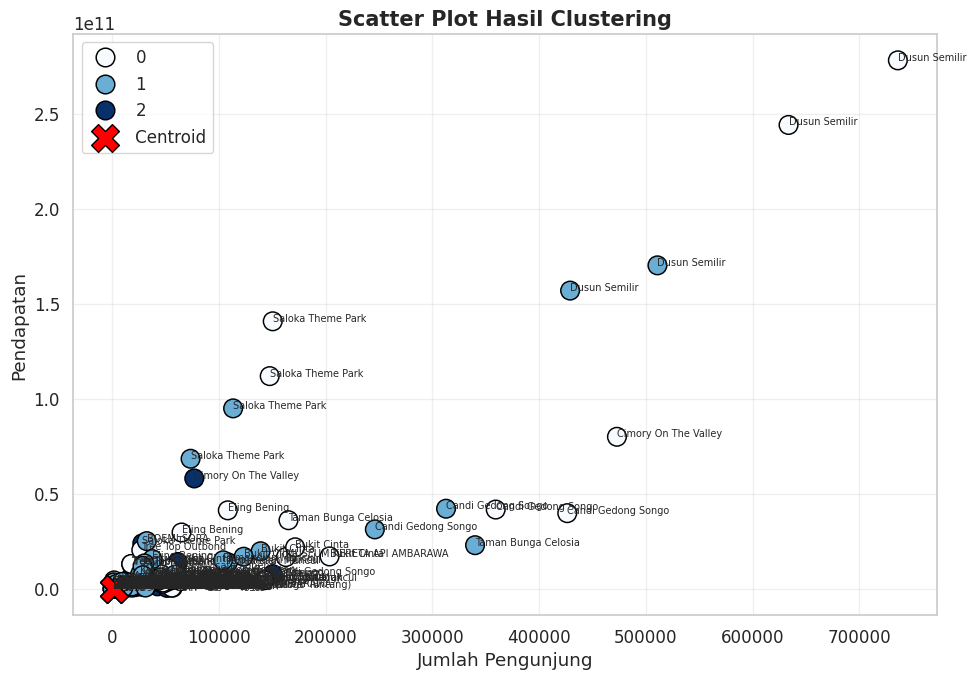

In [ ]:
# 1. Scatter Plot Hasil Clustering

plt.figure(figsize=(10,7))

ax = sns.scatterplot(
    data=df,
    x="Jumlah Pengunjung",
    y="Pendapatan",
    hue="Cluster",
    palette="Blues",
    s=180,
    edgecolor="black"
)

# Menampilkan nama destinasi
for i in range(len(df)):
    plt.text(
        df["Jumlah Pengunjung"].iloc[i],
        df["Pendapatan"].iloc[i],
        df["Nama Destinasi Wisata"].iloc[i],
        fontsize=7
    )

# Menampilkan centroid
try:
    centroid = scaler.inverse_transform(kmeans.cluster_centers_)

    plt.scatter(
        centroid[:,0],
        centroid[:,1],
        s=400,
        c="red",
        marker="X",
        edgecolor="black",
        label="Centroid"
    )

except:
    pass

plt.title("Scatter Plot Hasil Clustering", fontsize=15, weight="bold")
plt.xlabel("Jumlah Pengunjung")
plt.ylabel("Pendapatan")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()
plt.show()

Diagram sebar (scatter plot) di atas menggambarkan hasil klasterisasi destinasi wisata berdasarkan jumlah pengunjung ('Jumlah Pengunjung') dan pendapatan ('Pendapatan'), yang dilengkapi titik centroid untuk masing-masing klaster.

1.	Klaster 0 (berwarna putih) mewakili destinasi dengan jumlah pengunjung dan pendapatan tertinggi, ditandai dengan pencilan (outlier) ekstrem seperti Dusun Semilir yang berada jauh di kanan atas diagram.
2.	Klaster 1 (biru muda) menempati posisi menengah, diwakili oleh destinasi seperti Saloka Theme Park dan Cimory On The Valley, yang memiliki tren pendapatan dan pengunjung di atas rata-rata mayoritas data.
3.	Klaster 2 (biru tua) sebagian besar mengumpul padat pada area kiri bawah diagram, menunjukkan mayoritas destinasi wisata memiliki jumlah pengunjung dan pendapatan yang relatif paling rendah.
4.	Seluruh titik centroid (ditandai dengan simbol silang merah) berada di area kiri bawah sejajar dengan sebaran padat datanya, namun centroid pada klaster 0 dan 1 sedikit tertarik ke kanan atas akibat pengaruh destinasi-destinasi bernilai ekstrem.


/tmp/ipykernel_2803/2588837508.py:5: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  ax = sns.countplot(


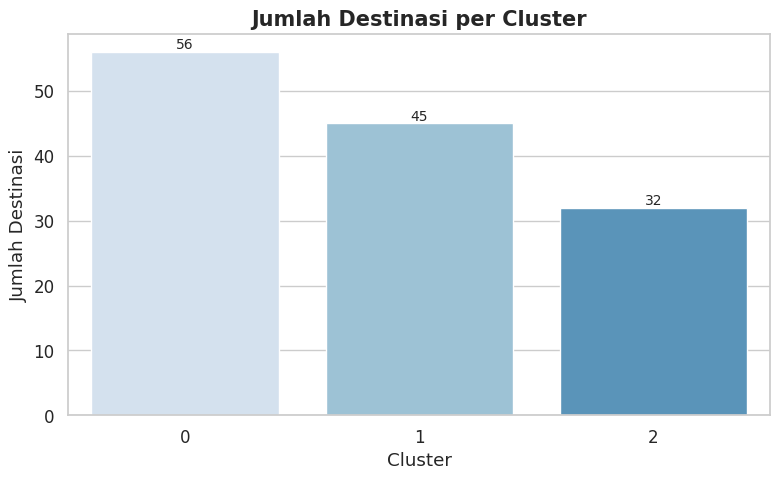

In [ ]:
# 2. Jumlah Destinasi per Cluster

plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x="Cluster",
    hue="Cluster",
    palette=palette,
    legend=False
)

plt.title("Jumlah Destinasi per Cluster", fontsize=15, weight="bold")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Destinasi")

for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.tight_layout()
plt.show()

Diagram batang di atas menggambarkan jumlah total destinasi wisata ('Jumlah Destinasi') pada masing-masing klaster ('Cluster') secara keseluruhan.

1.	Klaster 0 memiliki jumlah destinasi terbanyak, yaitu 56 destinasi.
2.	Klaster 1 berada di posisi kedua dengan 45 destinasi.
3.	Klaster 2 memiliki jumlah destinasi paling sedikit, yaitu 32 destinasi.


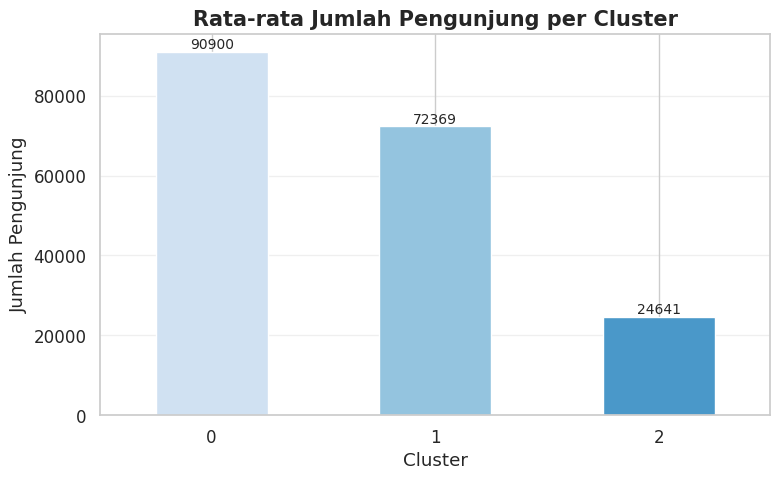

In [ ]:
# 3. Rata-rata Pengunjung per Cluster

avg_pengunjung = df.groupby("Cluster")["Jumlah Pengunjung"].mean()

ax = avg_pengunjung.plot(
    kind="bar",
    figsize=(8,5),
    color=palette
)

plt.title("Rata-rata Jumlah Pengunjung per Cluster", fontsize=15, weight="bold")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Pengunjung")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=10)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Diagram batang di atas menggambarkan rata-rata jumlah pengunjung ('Jumlah Pengunjung') pada masing-masing klaster ('Cluster').

1.	Klaster 0 memiliki rata-rata jumlah pengunjung tertinggi dibandingkan klaster lain, yaitu sebesar 90.900 pengunjung.
2.	Klaster 1 berada di posisi kedua dengan rata-rata sebesar 72.369 pengunjung.
3.	Klaster 2 memiliki rata-rata terendah yang berjarak cukup jauh dari klaster lainnya, yaitu sebesar 24.641 pengunjung.


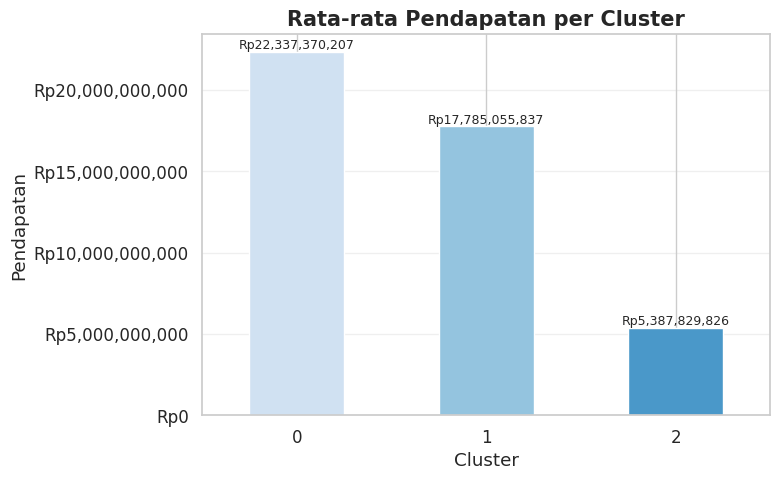

In [ ]:
# 4. Rata-rata Pendapatan per Cluster

avg_pendapatan = df.groupby("Cluster")["Pendapatan"].mean()

ax = avg_pendapatan.plot(
    kind="bar",
    figsize=(8,5),
    color=palette
)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f'Rp{x:,.0f}')
)

plt.title("Rata-rata Pendapatan per Cluster", fontsize=15, weight="bold")
plt.xlabel("Cluster")
plt.ylabel("Pendapatan")
plt.xticks(rotation=0)

for container in ax.containers:
    labels = [
        f"Rp{bar.get_height():,.0f}"
        for bar in container
    ]
    ax.bar_label(container, labels=labels, fontsize=9)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Diagram batang di atas menggambarkan rata-rata jumlah pendapatan (‘Pendapatan’) pada masing-masing klaster ('Cluster').

1.	Klaster 0 memiliki rata-rata pendapatan tertinggi, yaitu mencapai Rp22.337.370.207.
2.	Klaster 1 menempati posisi kedua dengan rata-rata pendapatan sebesar Rp17.785.055.837.
3.	Klaster 2 memiliki rata-rata pendapatan paling rendah, yaitu sebesar Rp5.387.829.826.


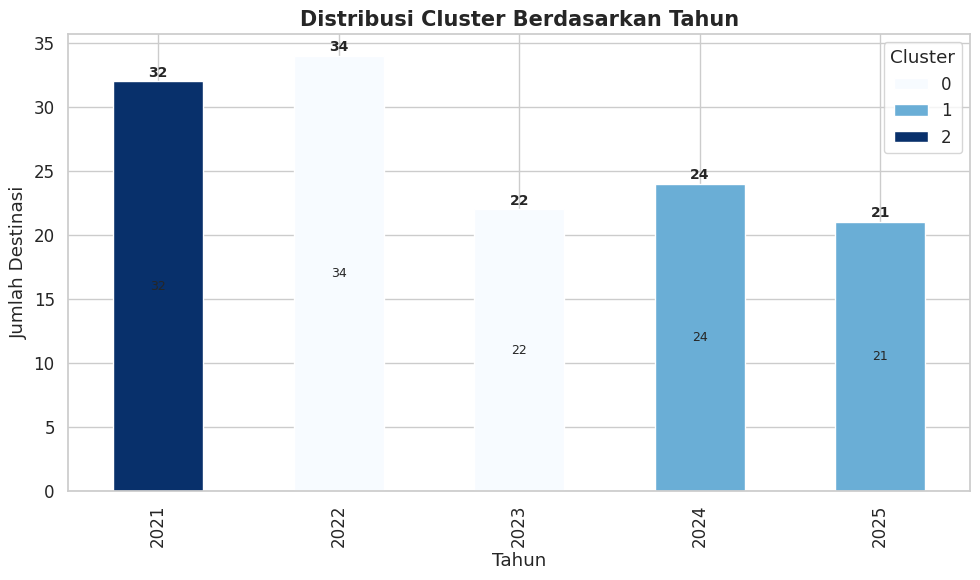

In [ ]:
# 5. Distribusi Cluster Berdasarkan Tahun

cluster_tahun = pd.crosstab(
    df["Tahun"],
    df["Cluster"]
)

ax = cluster_tahun.plot(
    kind="bar",
    stacked=True,
    figsize=(10,6),
    colormap="Blues"
)

plt.title("Distribusi Cluster Berdasarkan Tahun", fontsize=15, weight="bold")
plt.xlabel("Tahun")
plt.ylabel("Jumlah Destinasi")

for container in ax.containers:

    labels = [
        str(int(bar.get_height()))
        if bar.get_height() > 0 else ""
        for bar in container
    ]

    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        fontsize=9
    )

# Total tiap tahun

total = cluster_tahun.sum(axis=1)

for i, value in enumerate(total):

    ax.text(
        i,
        value + 0.4,
        str(value),
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

Diagram batang di atas menggambarkan distribusi jumlah destinasi wisata ('Jumlah Destinasi') berdasarkan tahun ('Tahun') dan klaster ('Cluster').

1.	Pada tahun 2021, seluruh data destinasi (sebanyak 32 destinasi) terkonsentrasi penuh pada Klaster 2.
2.	Pada tahun 2022, pergeseran terjadi secara total ke Klaster 0 dengan 34 destinasi.
3.	Pada tahun 2023, dominasi masih dipegang oleh Klaster 0 namun jumlahnya menurun menjadi 22 destinasi.
4.	Pada tahun 2024, pengelompokan berpindah ke Klaster 1 dengan total 24 destinasi.
5.	Pada tahun 2025, Klaster 1 tetap menjadi satu-satunya klaster yang terisi dengan 21 destinasi.


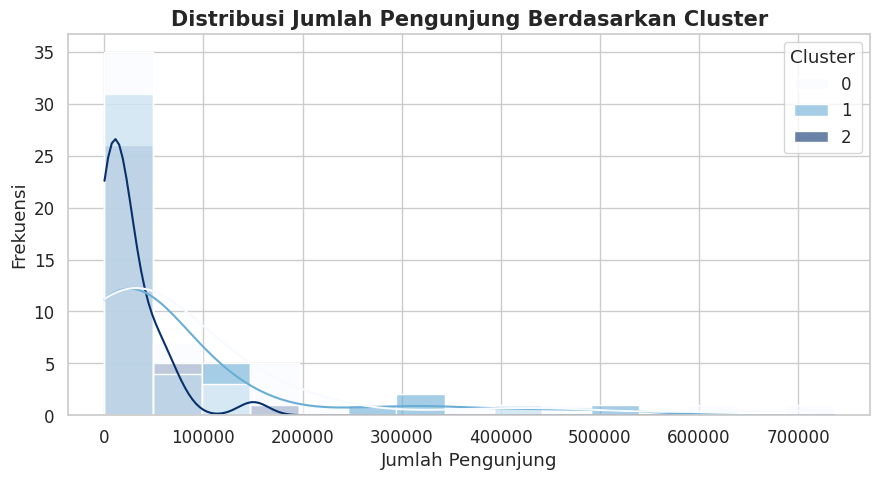

In [ ]:
# 6. Histogram Distribusi Pengunjung

plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="Jumlah Pengunjung",
    hue="Cluster",
    palette="Blues",
    bins=15,
    kde=True,
    alpha=0.6
)

plt.title("Distribusi Jumlah Pengunjung Berdasarkan Cluster", fontsize=15, weight="bold")
plt.xlabel("Jumlah Pengunjung")
plt.ylabel("Frekuensi")

plt.tight_layout()
plt.show()

Histogram di atas menggambarkan distribusi frekuensi jumlah pengunjung ('Jumlah Pengunjung') pada masing-masing klaster ('Cluster'), yang dilengkapi dengan kurva kepadatan (KDE) untuk melihat pola sebarannya.

1.	Sebagian besar destinasi pada seluruh klaster terkonsentrasi pada rentang jumlah pengunjung rendah, yaitu di bawah 100.000 pengunjung.
2.	Klaster 2 (biru tua) menunjukkan puncak kurva tertinggi pada rentang paling kiri, menandakan mayoritas anggotanya memiliki jumlah pengunjung yang memusat di angka kecil.
3.	Klaster 0 (putih) dan Klaster 1 (biru muda) memiliki sebaran ekor yang lebih panjang ke arah kanan (right-skewed), menunjukkan adanya beberapa destinasi dengan jumlah pengunjung yang jauh melebihi rata-rata hingga menyentuh angka 700.000 pengunjung.


/tmp/ipykernel_2803/3179796209.py:5: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  sns.boxplot(


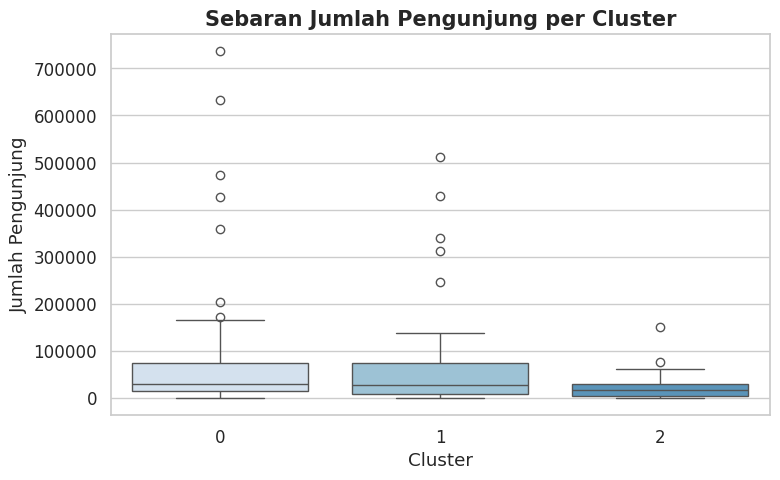

In [ ]:
# 7. Boxplot Sebaran Pengunjung

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="Cluster",
    y="Jumlah Pengunjung",
    hue="Cluster",
    palette=palette,
    legend=False
)

plt.title("Sebaran Jumlah Pengunjung per Cluster", fontsize=15, weight="bold")
plt.xlabel("Cluster")
plt.ylabel("Jumlah Pengunjung")

plt.tight_layout()
plt.show()

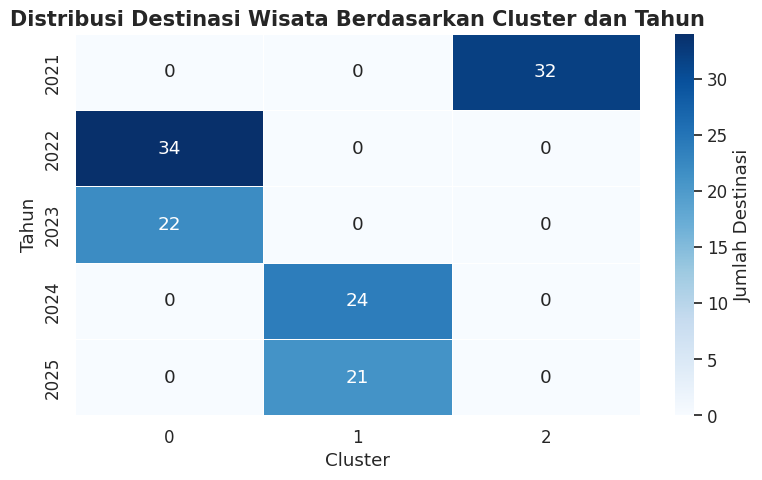

In [ ]:
# 8. Heatmap Distribusi Cluster per Tahun


cluster_tahun = pd.crosstab(
    df["Tahun"],
    df["Cluster"]
)

plt.figure(figsize=(8,5))

sns.heatmap(
    cluster_tahun,
    annot=True,
    cmap="Blues",
    fmt="d",
    linewidths=.5,
    cbar_kws={"label":"Jumlah Destinasi"}
)

plt.title(
    "Distribusi Destinasi Wisata Berdasarkan Cluster dan Tahun",
    fontsize=15,
    weight="bold"
)

plt.xlabel("Cluster")
plt.ylabel("Tahun")

plt.tight_layout()
plt.show()

Peta panas (heatmap) di atas menggambarkan matriks distribusi jumlah destinasi wisata berdasarkan tahun ('Tahun') dan klaster ('Cluster'). Intensitas warna biru yang semakin gelap menunjukkan jumlah data yang semakin banyak.

1.	Pada tahun 2021, data hanya terisi pada Klaster 2 sebanyak 32 destinasi (diwakili warna biru tua).
2.	Pada tahun 2022, sebaran data berpindah sepenuhnya ke Klaster 0 dengan 34 destinasi (diwakili warna biru paling gelap).
3.	Pada tahun 2023, data masih dominan di Klaster 0 dengan 22 destinasi (diwakili warna biru menengah).
4.	Pada tahun 2024 dan 2025, data secara utuh menempati Klaster 1, dengan rincian 24 destinasi pada 2024 dan 21 destinasi pada 2025 (keduanya diwakili warna biru menengah).


**ANALISIS PERUBAHAN JUMLAH PENGUNJUNG DAN PENDAPATAN**

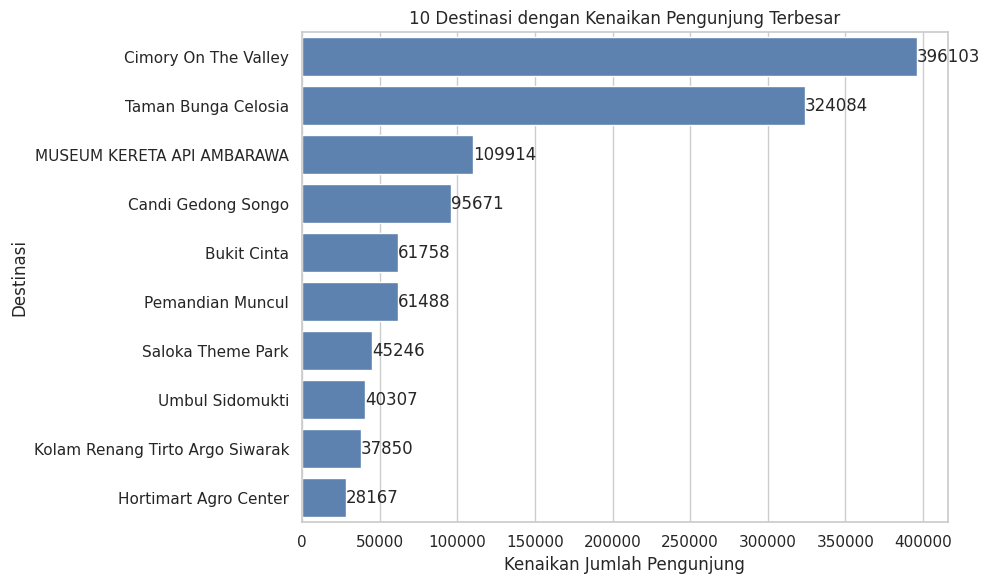

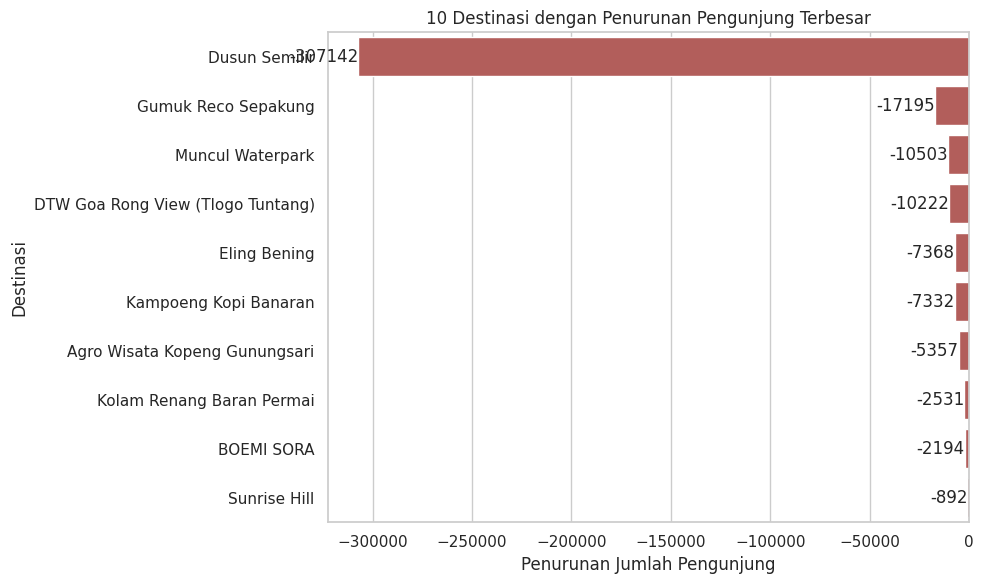



RATA-RATA PERUBAHAN SETIAP CLUSTER


,Perubahan Pengunjung,Perubahan Pendapatan
Cluster,,
0,"-33,991","Rp-12,554,966,499"
1,-396,"Rp-1,908,367,238"
2,"+39,244","Rp+5,395,620,716"


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Calculate the change in 'Jumlah Pengunjung' and 'Pendapatan' for each destination
# For each destination, find the earliest and latest year's values
df_sorted = df.sort_values(by=['Nama Destinasi Wisata', 'Tahun'])

# Get values for the earliest year for each destination
earliest_values = df_sorted.groupby('Nama Destinasi Wisata').first().reset_index()
earliest_values = earliest_values[['Nama Destinasi Wisata', 'Jumlah Pengunjung', 'Pendapatan', 'Cluster']].rename(columns={
    'Jumlah Pengunjung': 'Jumlah Pengunjung_earliest',
    'Pendapatan': 'Pendapatan_earliest'
})

# Get values for the latest year for each destination
latest_values = df_sorted.groupby('Nama Destinasi Wisata').last().reset_index()
latest_values = latest_values[['Nama Destinasi Wisata', 'Jumlah Pengunjung', 'Pendapatan']].rename(columns={
    'Jumlah Pengunjung': 'Jumlah Pengunjung_latest',
    'Pendapatan': 'Pendapatan_latest'
})

# Merge these two dataframes
hasil = pd.merge(earliest_values, latest_values, on='Nama Destinasi Wisata')

# Calculate the change
hasil['Perubahan Pengunjung'] = hasil['Jumlah Pengunjung_latest'] - hasil['Jumlah Pengunjung_earliest']
hasil['Perubahan Pendapatan'] = hasil['Pendapatan_latest'] - hasil['Pendapatan_earliest']

# Drop intermediate columns if not needed
hasil = hasil.drop(columns=[
    'Jumlah Pengunjung_earliest', 'Pendapatan_earliest',
    'Jumlah Pengunjung_latest', 'Pendapatan_latest'
])

# TOP 10 KENAIKAN PENGUNJUNG

top_naik = hasil.nlargest(10, "Perubahan Pengunjung")

plt.figure(figsize=(10,6))

ax = sns.barplot(
    data=top_naik.reset_index(),
    y="Nama Destinasi Wisata",
    x="Perubahan Pengunjung",
    color="#4F81BD"
)

plt.title("10 Destinasi dengan Kenaikan Pengunjung Terbesar")
plt.xlabel("Kenaikan Jumlah Pengunjung")
plt.ylabel("Destinasi")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

# TOP 10 PENURUNAN PENGUNJUNG

top_turun = hasil.nsmallest(10, "Perubahan Pengunjung")

plt.figure(figsize=(10,6))

ax = sns.barplot(
    data=top_turun.reset_index(),
    y="Nama Destinasi Wisata",
    x="Perubahan Pengunjung",
    color="#C0504D"
)

plt.title("10 Destinasi dengan Penurunan Pengunjung Terbesar")
plt.xlabel("Penurunan Jumlah Pengunjung")
plt.ylabel("Destinasi")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

# RINGKASAN PER CLUSTER

ringkasan = hasil.groupby("Cluster").agg({

    "Perubahan Pengunjung":"mean",
    "Perubahan Pendapatan":"mean"

}).round(0)

print("\n")
print("RATA-RATA PERUBAHAN SETIAP CLUSTER")

display(
    ringkasan.style.format({

        "Perubahan Pengunjung":"{:+,.0f}",
        "Perubahan Pendapatan":"Rp{:+,.0f}"

    })
)